# Testing the FFT overlay you built (tutorial, part 3)

This notebook belongs to `tutorial/TUTORIAL.md`. You added a streaming FFT to the P501 block design, built the bitstream and copied
`p501_fft_tut.bit` / `.hwh` to the board. Here we load that overlay and test it in four small steps, each with a `PASS` / `FAIL`:

| test | what it shows |
|---|---|
| 0 | the overlay loads, the new DMA is where the block design put it |
| 1 | the FFT chain delivers frames even with no signal (the data path is alive) |
| 2 | a transmitted tone shows up in the FFT bin it belongs to, for several bins |
| 3 | every frame of a long transfer carries data (the DMA is not cut short) |
| 4 | the FPGA result matches NumPy's FFT of the raw samples (scaling, bit growth) |

**Setup:** TX1 and RX1 antennas near each other, or a cable with at least 40 dB attenuation - never connect them directly.
The AD9361 itself is configured from Python (SPI), exactly as in `P501_AD9361_Test.ipynb`.

## Configuration

In [1]:
BIT       = "/home/xilinx/jupyter_notebooks/p501_fft_tut/p501_fft_tut.bit"   # the overlay you built (the .hwh must sit next to it)
NFFT_LOG2 = 10                 # the value of fft_nlog2 you used in the tutorial
SCALE_SHIFT = NFFT_LOG2 - 4    # the value of fft_scale_shift you used (tutorial default: NFFT_LOG2 - 4)
N         = 1 << NFFT_LOG2     # FFT length
FS        = 3_840_000          # sample rate (3.84 MSPS preset of the AD9361 driver)
LO        = 700_000_000        # RF centre frequency, Hz
RF_BW     = 4_000_000          # analog bandwidth, Hz
TONE_BIN  = 267                # default test tone: exactly on this FFT bin (frequency = bin * FS / N)
FRAMES    = 64                 # FFT frames per DMA transfer
TX_ATTEN  = 10                 # dB
RX_GAIN   = 45                 # gain-table index 0..76
SETTLE_DB = 45                 # image rejection the AD9361 bring-up waits for (see P501_AD9361_Test.ipynb)

## Test 0 - load the overlay

`Overlay(BIT)` programs the PL and parses the `.hwh`. Every IP of the block design shows up as an attribute, so the DMA you added
in step 5 of the tutorial is simply `ol.fft_dma`. We use the same `AxiDmac` helper as for the two ADI DMAs that were already there.

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from pynq import Overlay, allocate

sys.path.insert(0, '/home/xilinx/jupyter_notebooks')
from ad9361_driver import (AD9361, FIR_RX1, FIR_TX1,
                           REG_ENSM_CONFIG_1, TO_ALERT, FORCE_ALERT_STATE)
from axi_dmac import AxiDmac
import ad9361_full_bypass_test as fb
from ad9361_fir_test import make_fir_coef

results = {}
def check(name, ok, detail):
    results[name] = (bool(ok), detail)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: {detail}")

ol   = Overlay(BIT)                              # loads the bitstream
txd  = AxiDmac(ol.axi_ad9361_dac_dma)            # TX samples      (was already in the design)
rxd  = AxiDmac(ol.axi_ad9361_adc_dma)            # raw ADC capture (was already in the design)
fftd = AxiDmac(ol.fft_dma)                       # FFT output      (the DMA you added)

addr = ol.ip_dict["fft_dma"]["phys_addr"]
ver  = ol.fft_dma.read(0x000)                    # ADI cores have a version register at offset 0
check("overlay loaded", addr == 0x9C440000 and ver != 0,
      f"fft_dma at 0x{addr:08X}, core version 0x{ver:08X}")

PASS  overlay loaded: fft_dma at 0x9C440000, core version 0x00040461


## AD9361 bring-up

This cell is the software side, unchanged from the base design (clocks, LO, calibrations, FIR, then `settle` waits for a clean
image rejection - a known AD9361 analog-state quirk described in the bring-up report). It also defines the helpers used below:
`tone_buffer_bin(k)` builds a TX buffer with a tone exactly on FFT bin *k* and `capture_adc()` grabs raw ADC samples.
Nothing in it depends on the FFT.

In [3]:
M_TX = 8192                                       # samples in the TX loop buffer

def tone_buffer_bin(k):
    """Complex tone exactly on FFT bin k of the N-point FFT (whole cycles in the TX buffer, no leakage)."""
    cycles = k * (M_TX // N)
    t = np.exp(2j * np.pi * cycles * np.arange(M_TX) / M_TX) * 0.5 * (2**15 - 1)
    tx = allocate(shape=(M_TX * 2,), dtype=np.int16)
    tx[0::2] = t.real.astype(np.int16)
    tx[1::2] = t.imag.astype(np.int16)
    tx.flush()
    return tx, k * FS / N

def capture_adc(n=8192, tx=None):
    rx = allocate(shape=(n * 2,), dtype=np.int16)
    ok = rxd.transfer_to_memory(rx.physical_address, rx.nbytes)
    rx.invalidate()
    a = np.array(rx); rx.freebuffer()
    return ok, a[0::2].astype(float) + 1j * a[1::2].astype(float)

def settle(ad, min_rej_db=SETTLE_DB, max_tries=40):
    """Re-enable the chip until the image rejection of a test tone is good (known AD9361 analog-state issue)."""
    tx, f = tone_buffer_bin(TONE_BIN)
    freqs = np.fft.fftshift(np.fft.fftfreq(8192, 1 / FS))
    for tries in range(1, max_tries + 1):
        txd.transfer_from_memory(tx.physical_address, tx.nbytes, cyclic=True)
        ok, x = capture_adc()
        txd.stop()
        x = x - x.mean()
        m = 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(x * np.hanning(len(x))))) + 1e-9)
        sel = lambda f0: m[np.abs(freqs - f0) < 25e3].max()
        rej = sel(f) - sel(-f)
        if rej >= min_rej_db:
            break
        ad.reg_write(REG_ENSM_CONFIG_1, TO_ALERT | FORCE_ALERT_STATE)
        if tries % 8 == 0:
            ad.tx_quad_calib(RF_BW // 2, RF_BW // 2)
        ad.enable_fdd()
        fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
    tx.freebuffer()
    return rej, tries

try:
    ad.close()
except NameError:
    pass
ad = AD9361()
ad.power_up_clocks()
assert ad.set_bbpll_rate(983_040_000), "BBPLL did not lock"
ad.set_clock_chain()                                          # 3.84 MSPS
ad.synth_cp_calib(False); ad.synth_cp_calib(True)
rx_ok = ad.set_rx_lo_freq(LO); tx_ok = ad.set_tx_lo_freq(LO)
ad.enable_rx1_tx1()
fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_1, fb.PP_CONF_1)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_2, fb.PP_CONF_2)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_3, fb.PP_CONF_3_LVDS_MODE)
ad.reg_write(fb.REG_RX_CLOCK_DATA_DELAY, fb.RX_CLOCK_DATA_DELAY)
ad.reg_write(fb.REG_TX_CLOCK_DATA_DELAY, fb.TX_CLOCK_DATA_DELAY)
ad.reg_write(fb.REG_LVDS_BIAS_CTRL, fb.LVDS_BIAS_CTRL)
cal = ad.analog_init(rf_rx_bw_hz=RF_BW, rf_tx_bw_hz=RF_BW, rx_freq_hz=LO)
ad.set_rx_manual_gain(RX_GAIN)
ad.set_tx_atten_db(TX_ATTEN)
ad.enable_fdd()
coef = make_fir_coef()
ad.load_fir_filter_coef(FIR_RX1, 0, coef)
ad.load_fir_filter_coef(FIR_TX1, 0, coef)
fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
rej, tries = settle(ad)
print(f"product id 0x{ad.product_id():02X}, ENSM 0x{ad.ensm_state():X}, LO locks {rx_ok}/{tx_ok}, settled after {tries} tries ({rej:.1f} dB image rejection)")
check("AD9361 up", ad.product_id_ok() and rx_ok and tx_ok and ad.ensm_state() == 0xA, f"calibrations {cal}")

product id 0x0A, ENSM 0xA, LO locks True/True, settled after 18 tries (45.5 dB image rejection)
PASS  AD9361 up: calibrations {'rx_bb_filter': True, 'tx_bb_filter': True, 'bb_dc': True, 'rf_dc': True, 'tx_quad': 3}


## A helper that reads FFT frames

The FFT chain is *free running*: it transforms the ADC stream all the time. The frame gate (`fft_power`) lets a frame pass only while the
DMA has a transfer pending, so a transfer always starts on a frame boundary: ask the DMA for `frames x N x 4` bytes and
you get that many whole frames of 32-bit power values, bin 0 first (natural order, `fftshift` for a centred plot).

In [4]:
def read_frames(n_frames=FRAMES, timeout_s=5.0):
    """Power spectra from the FPGA: array (n_frames, N) of |X|^2, FFT natural order."""
    buf = allocate(shape=(n_frames, N), dtype=np.uint32)
    ok = fftd.transfer_to_memory(buf.physical_address, buf.nbytes, timeout_s=timeout_s)
    buf.invalidate()
    p = np.array(buf, dtype=np.float64)
    buf.freebuffer()
    return ok, p

db      = lambda p: 10 * np.log10(p + 1.0)
f_axis  = np.fft.fftshift(np.fft.fftfreq(N, 1 / FS)) / 1e3        # kHz
def peak_bin(p_avg):                                               # bin number relative to DC (-N/2 .. N/2-1)
    return int(np.argmax(np.fft.fftshift(p_avg))) - N // 2

## Test 1 - frames arrive with no signal

TX sends zeros. (Stopping the TX DMA is not enough: the DAC keeps replaying the last samples it received, so we transmit an explicit
buffer of zeros.) The receiver still delivers thermal noise, so we expect non-zero frames and a spectrum that is flat apart from a
spike at DC from the AD9361's own offset and LO leakage. If this fails the data path is broken (clock, reset, DMA wiring), before any signal question.

PASS  idle frames arrive: 8 frames x 1024 bins, floor 0.5 dB, strongest spur 35 dB over it


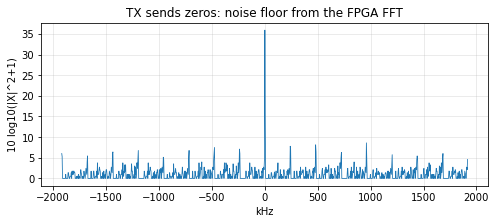

In [5]:
zeros = allocate(shape=(8192 * 2,), dtype=np.int16); zeros[:] = 0; zeros.flush()
txd.transfer_from_memory(zeros.physical_address, zeros.nbytes, cyclic=True)
ok1, p_idle = read_frames(8)
txd.stop(); zeros.freebuffer()
idle = p_idle.mean(axis=0)
floor_db = float(np.median(db(idle)))
quiet = np.fft.fftshift(db(idle)).max() - floor_db < 45          # no strong spurs: the transmitter really is silent
check("idle frames arrive", ok1 and p_idle.max() > 0 and quiet,
      f"8 frames x {N} bins, floor {floor_db:.1f} dB, strongest spur {np.fft.fftshift(db(idle)).max() - floor_db:.0f} dB over it")
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(f_axis, np.fft.fftshift(db(idle)), lw=0.8); ax.set(title="TX sends zeros: noise floor from the FPGA FFT", xlabel="kHz", ylabel="10 log10(|X|^2+1)"); ax.grid(alpha=.3)
plt.show()

## Test 2 - a tone appears in its bin

We transmit a complex tone exactly on bin *k* (frequency *k*·fs/N) and check that the FPGA's spectrum peaks at bin *k*.
Three bins, including a negative one (upper half of the FFT output). Negative frequency bins are the mirror of positive ones, so
this also checks the I/Q order of the data into the FFT: swapped I and Q would put the tones in the mirrored bins.

In [6]:
test_bins = [100, TONE_BIN, -180]
found = {}
for k in test_bins:
    tx, f_t = tone_buffer_bin(k % N)
    txd.transfer_from_memory(tx.physical_address, tx.nbytes, cyclic=True)
    ok, p = read_frames(16)
    txd.stop(); tx.freebuffer()
    avg = p.mean(axis=0)
    found[k] = (ok, peak_bin(avg), db(avg[k % N]) - float(np.median(db(avg))))
good = all(ok and abs(pk - k) <= 1 and margin > 30 for k, (ok, pk, margin) in found.items())
check("tone in the right bin", good,
      "; ".join(f"sent {k:+d} -> peak {pk:+d} ({m:.0f} dB over floor)" for k, (ok, pk, m) in found.items()))

PASS  tone in the right bin: sent +100 -> peak +100 (64 dB over floor); sent +267 -> peak +267 (64 dB over floor); sent -180 -> peak -180 (63 dB over floor)


## Test 3 - long transfers are not cut short

Regression test for a real bug found while building this overlay: the ADI DMA ends a transfer at the first `TLAST`, so with
`TLAST` wired to the DMA, a 64-frame transfer returned one frame and 63 frames of zeros. The gate does not forward `TLAST`
any more; this checks that every frame of a 64-frame transfer holds data.

In [7]:
tx, f_tone = tone_buffer_bin(TONE_BIN)
txd.transfer_from_memory(tx.physical_address, tx.nbytes, cyclic=True)
P_hw_ok, P_hw = read_frames(FRAMES)                                   # FRAMES whole FFT frames from the FPGA
ok_raw, x_raw = capture_adc(8192)                                     # raw ADC samples, for test 4
txd.stop(); tx.freebuffer()
frame_peak = P_hw.max(axis=1)
check("all frames carry data", P_hw_ok and (frame_peak > 0).all(),
      f"{int((frame_peak > 0).sum())}/{FRAMES} frames non-empty, peak power per frame {frame_peak.min():.3g} .. {frame_peak.max():.3g}")

PASS  all frames carry data: 64/64 frames non-empty, peak power per frame 2.41e+06 .. 2.43e+06


## Test 4 - same answer as NumPy

The reference is NumPy's FFT of a raw ADC capture taken at the same time (the original ADC DMA path, untouched by the FFT chain),
divided by `4**SCALE_SHIFT`: the FFT core's scaling schedule divides the *amplitude* by `2**SCALE_SHIFT`, so the power by `4**SCALE_SHIFT`.
The FFT core rounds to 16 bits, so we only compare where the signal is far above the rounding noise: at the tone.

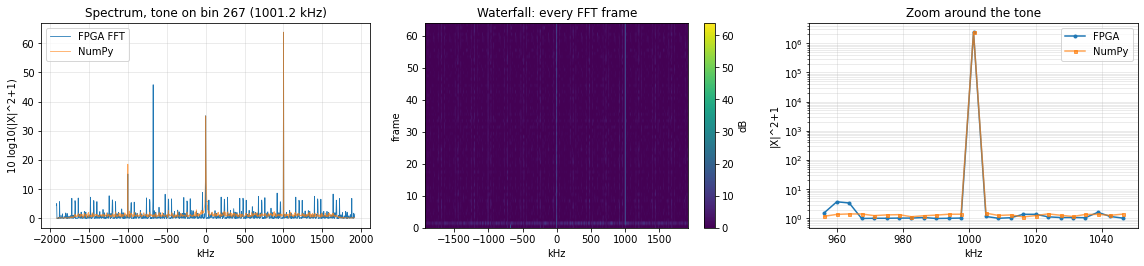

PASS  matches NumPy at the tone: FPGA / NumPy = -0.05 dB
PASS  no overflow: max power 2.43e+06 (limit 2^31 = 2.15e+09)


In [8]:
hw_avg  = np.fft.fftshift(P_hw.mean(axis=0))
blocks  = x_raw[: (len(x_raw) // N) * N].reshape(-1, N)
ref_avg = np.fft.fftshift((np.abs(np.fft.fft(blocks, axis=1)) ** 2).mean(axis=0)) / 4.0 ** SCALE_SHIFT

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(f_axis, db(hw_avg), lw=0.8, label="FPGA FFT"); ax[0].plot(f_axis, db(ref_avg), lw=0.8, alpha=0.7, label="NumPy")
ax[0].set(title=f"Spectrum, tone on bin {TONE_BIN} ({f_tone/1e3:.1f} kHz)", xlabel="kHz", ylabel="10 log10(|X|^2+1)"); ax[0].legend(); ax[0].grid(alpha=.3)
im = ax[1].imshow(db(np.fft.fftshift(P_hw, axes=1)), aspect="auto", origin="lower", extent=[f_axis[0], f_axis[-1], 0, FRAMES], cmap="viridis")
ax[1].set(title="Waterfall: every FFT frame", xlabel="kHz", ylabel="frame"); fig.colorbar(im, ax=ax[1], label="dB")
c = N // 2 + TONE_BIN
ax[2].semilogy(f_axis[c-12:c+13], hw_avg[c-12:c+13] + 1, "o-", ms=3, label="FPGA"); ax[2].semilogy(f_axis[c-12:c+13], ref_avg[c-12:c+13] + 1, "s-", ms=3, alpha=.7, label="NumPy")
ax[2].set(title="Zoom around the tone", xlabel="kHz", ylabel="|X|^2+1"); ax[2].legend(); ax[2].grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()

ratio_db = 10 * np.log10((hw_avg[c] + 1) / (ref_avg[c] + 1))
check("matches NumPy at the tone", ok_raw and abs(ratio_db) < 3, f"FPGA / NumPy = {ratio_db:+.2f} dB")
check("no overflow", P_hw.max() < 2**31 - 1, f"max power {P_hw.max():.3g} (limit 2^31 = {2**31:.3g})")

## Summary

In [9]:
bad = [k for k, (ok, _) in results.items() if not ok]
print("ALL TESTS PASSED" if not bad else "SOME TESTS FAILED: " + ", ".join(bad))

ALL TESTS PASSED


### If a test fails

| symptom | likely cause |
|---|---|
| `Overlay(BIT)` raises an error about connections / `pynqmetadata` | the `.hwh` was not fixed with `tools/fix_hwh.py` (tutorial step 8) |
| test 0: `fft_dma` missing or at another address | `assign_bd_address` in step 5 was skipped, or the wrong `.hwh` is next to the `.bit` |
| test 1: DMA times out | the FFT side gets no clock/reset (check step 1 connections), or `fft_dma/s_axis_xfer_req` is not wired to `fft_power/frame_en` |
| test 2: peak in the mirrored bin | I and Q swapped at the framer input (`smp_i` / `smp_q`) |
| test 3: only the first frame has data | `TLAST` reaches the DMA (`m_axis_tlast` in `fft_power_gate.v` must stay low) |
| test 4: constant offset of 6 dB steps | `fft_scale_shift` in the design differs from `SCALE_SHIFT` in this notebook |
| test 4: tone flat-topped / garbled | FFT overflow: raise `fft_scale_shift` and rebuild |

### Things to try

* Change `TONE_BIN`, `LO` or `FS` (re-run the bring-up cell with another preset of `ad9361_driver`).
* Rebuild with `fft_nlog2 = 12` (`NFFT_LOG2` here too) for a 4096-point FFT: finer bins, same hardware recipe.
* Add a Hann window in front of the FFT, or average several frames in BRAM, to get a cleaner floor (see `tutorial/TUTORIAL.md`, section "Where to go next").